# 02 — Exploratory Data Analysis
**Project:** Planetary Defense Analytics  
**Goal:** Understand distributions, skew, outliers, target relationships and multicollinearity. No cleaning here, only *decisions* to carry into `03_cleaning_features.ipynb`.

## 1. Setup & load

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RNG = 42

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW_FILE = sorted((ROOT / "data" / "raw").glob("*.csv"))[0]
FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "reports" / "results"; RES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()

USE = ["full_name", "neo", "pha", "H", "diameter", "albedo", "e", "a", "q", "i",
       "om", "w", "ma", "ad", "n", "per_y", "moid", "moid_ld", "class", "rms"]
df = pd.read_csv(RAW_FILE, usecols=USE, low_memory=False)
print(df.shape, f"| {df.memory_usage(deep=True).sum()/1e6:.0f} MB")

# Plot sample (full data is used for every statistic; the sample is only for drawing)
samp = df.sample(150_000, random_state=RNG)

(958524, 20) | 176 MB


## 2. Categorical features: `neo`, `pha`, `class`

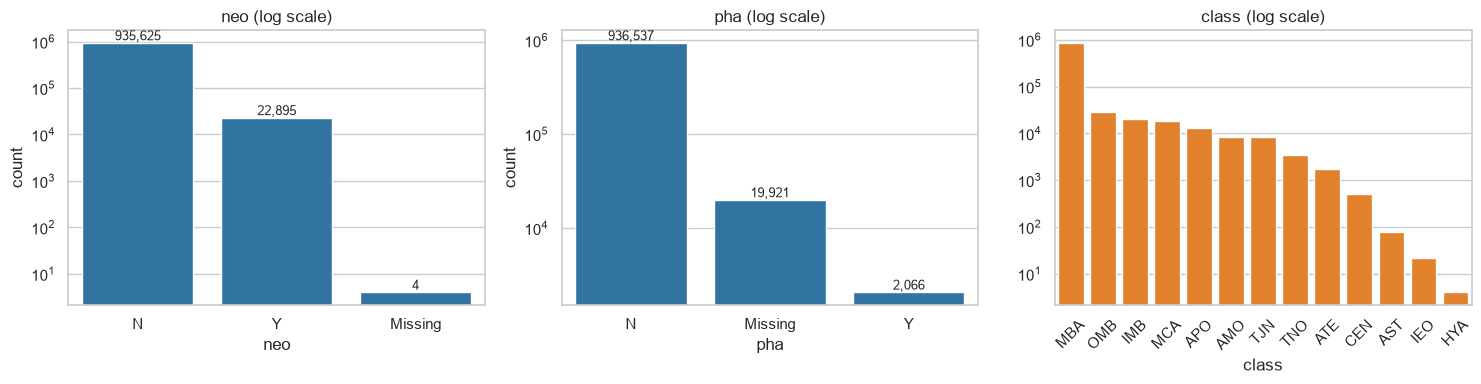

PHA (labelled rows): 2,066 Y vs 936,537 N  ->  0.220% positive, 1 : 453


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes[:2], ["neo", "pha"]):
    vc = df[col].fillna("Missing").value_counts()
    sns.barplot(x=vc.index, y=vc.values, ax=ax, color="tab:blue")
    ax.set_yscale("log"); ax.set_title(f"{col} (log scale)"); ax.set_ylabel("count")
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

vc = df["class"].value_counts()
sns.barplot(x=vc.index, y=vc.values, ax=axes[2], color="tab:orange")
axes[2].set_yscale("log"); axes[2].set_title("class (log scale)"); axes[2].tick_params(axis="x", rotation=45)
savefig("02_categorical_counts")

lab = df.dropna(subset=["pha"])
n_y = (lab["pha"] == "Y").sum(); n_n = (lab["pha"] == "N").sum()
print(f"PHA (labelled rows): {n_y:,} Y vs {n_n:,} N  ->  {n_y/len(lab)*100:.3f}% positive, 1 : {n_n/n_y:.0f}")

## 3. Univariate: numeric distributions

In [3]:
num_feats = ["e", "a", "i", "H", "diameter", "albedo", "moid", "per_y", "n", "rms"]

stats = pd.DataFrame({
    "min": df[num_feats].min(), "median": df[num_feats].median(), "max": df[num_feats].max(),
    "mean": df[num_feats].mean(), "skew": df[num_feats].skew(), "kurtosis": df[num_feats].kurt(),
    "missing_%": df[num_feats].isna().mean() * 100,
}).round(4)
stats.sort_values("skew", key=abs, ascending=False)

,min,median,max,mean,skew,kurtosis,missing_%
rms,0.0000,0.5663,2.686600e+03,0.5612,976.7360,955513.1979,0.0002
per_y,0.0000,4.3066,6.128574e+06,13.9229,953.0061,921888.7303,0.0001
a,-14702.4479,2.6470,3.348890e+04,2.9021,577.4996,550590.6873,0.0000
diameter,0.0025,3.9720,9.394000e+02,5.5064,25.8524,1634.3631,85.7897
moid,0.0000,1.2408,7.947660e+01,1.4152,15.7556,264.6461,2.0783
n,0.0000,0.2289,2.381100e+00,0.2367,5.6235,63.7163,0.0000
i,0.0077,7.4157,1.750829e+02,9.0549,2.1837,20.7734,0.0000
e,0.0000,0.1450,1.855400e+00,0.1561,1.8989,7.9364,0.0000
albedo,0.0010,0.0790,1.000000e+00,0.1306,1.6836,3.9003,85.9051
H,-1.1000,16.9000,3.320000e+01,16.9064,0.6047,9.5328,0.6534


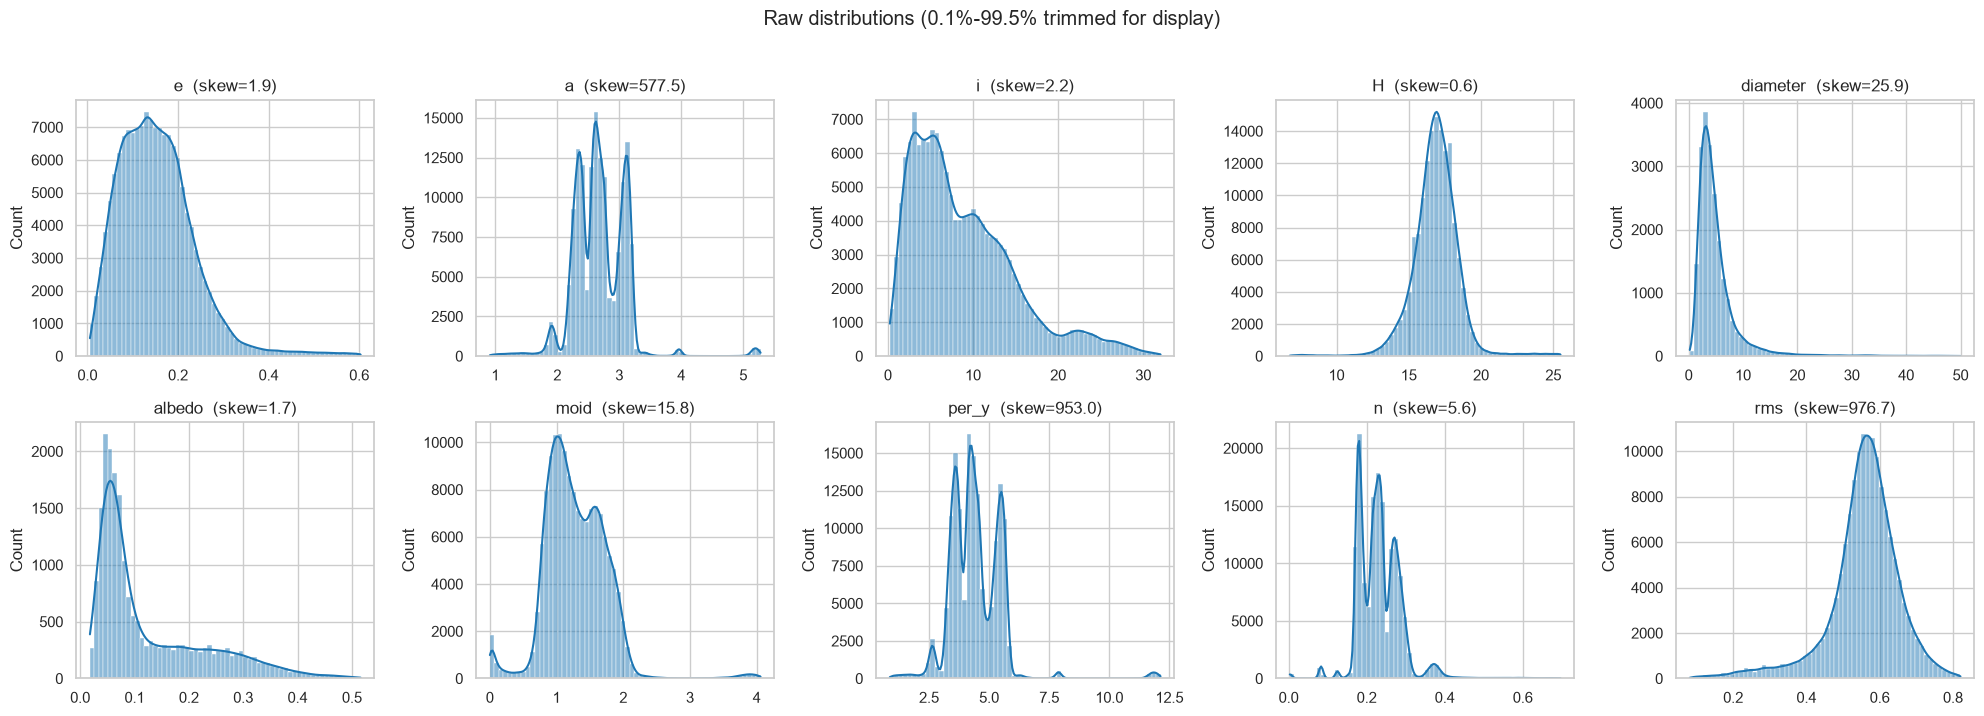

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.ravel(), num_feats):
    x = samp[c].dropna()
    lo, hi = x.quantile([0.001, 0.995])          # trim tails for display only
    sns.histplot(x[(x >= lo) & (x <= hi)], bins=60, kde=True, ax=ax, color="tab:blue")
    ax.set_title(f"{c}  (skew={df[c].skew():.1f})")
    ax.set_xlabel("")
fig.suptitle("Raw distributions (0.1%-99.5% trimmed for display)", y=1.02)
savefig("02_numeric_distributions")

### Heavily skewed features on a log scale


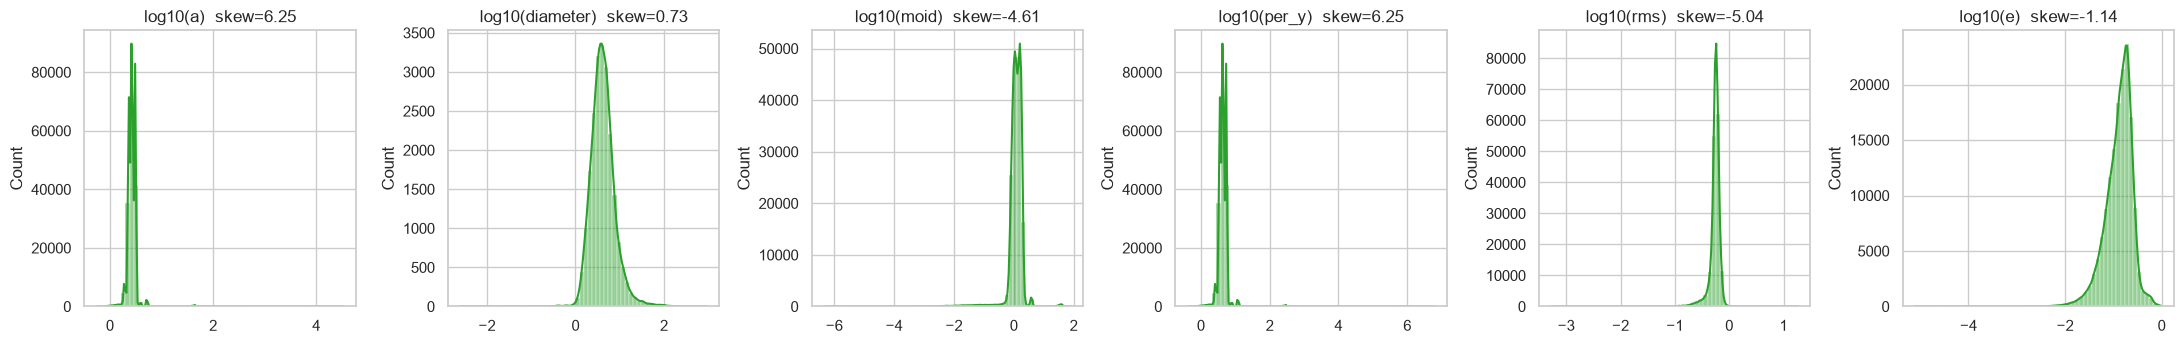

In [5]:
skewed = ["a", "diameter", "moid", "per_y", "rms", "e"]
fig, axes = plt.subplots(1, len(skewed), figsize=(22, 3.6))
for ax, c in zip(axes, skewed):
    x = samp[c].dropna(); x = x[x > 0]
    sns.histplot(np.log10(x), bins=60, kde=True, ax=ax, color="tab:green")
    ax.set_title(f"log10({c})  skew={np.log10(df.loc[df[c] > 0, c]).skew():.2f}")
    ax.set_xlabel("")
savefig("02_log_distributions")

## 4. Outliers (IQR) — genuine objects or data errors?

In [6]:
rows = []
for c in num_feats:
    x = df[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    rows.append({
        "feature": c,
        "outliers_1.5IQR_%": ((x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)).mean() * 100,
        "outliers_3IQR_%":   ((x < q1 - 3*iqr)   | (x > q3 + 3*iqr)).mean() * 100,
    })
out = pd.DataFrame(rows).set_index("feature").round(2)
out

,outliers_1.5IQR_%,outliers_3IQR_%
feature,,
e,2.59,0.92
a,2.60,1.28
i,3.16,0.17
H,4.68,1.89
diameter,7.06,3.43
albedo,2.63,0.29
moid,2.62,1.22
per_y,2.32,1.28
n,2.51,1.02


In [7]:
# Who are the 'outliers' in a, e, i? If they are TNO/CEN/comets-like classes they are real physics, not errors.
q1, q3 = df["a"].quantile([0.25, 0.75]); hi = q3 + 3 * (q3 - q1)
print("a beyond 3*IQR: class composition")
print(df.loc[df["a"] > hi, "class"].value_counts(normalize=True).round(3).head(6), "\n")

print("Highest e values:")
print(df.nlargest(5, "e")[["full_name", "class", "e", "a", "q"]].to_string(index=False), "\n")
print("Highest i values:")
print(df.nlargest(5, "i")[["full_name", "class", "i", "a"]].to_string(index=False))

a beyond 3*IQR: class composition
class
TJN    0.670
TNO    0.283
CEN    0.041
AST    0.005
AMO    0.001
APO    0.000
Name: proportion, dtype: float64 

Highest e values:
                   full_name class        e             a        q
                (2013 CA134)   HYA 1.855356     -6.149566 5.260067
       'Oumuamua (A/2017 U1)   HYA 1.201134     -1.272345 0.255912
                 (A/2019 O3)   HYA 1.001173  -7520.984443 8.820993
                 (A/2019 G4)   HYA 1.000398 -14702.447872 5.858539
                 (A/2019 Q1)   TNO 0.999851  33488.895955 4.995845 

Highest i values:
          full_name class          i         a
         (2013 LA2)   CEN 175.082901  5.669061
   434620 (2005 VD)   CEN 172.873123  6.673529
         (2006 LM1)   TNO 172.136146 32.186797
       (2016 EJ203)   TNO 170.979601 67.427405
         (2018 TL6)   CEN 170.918242  8.221900


## 5. Bivariate: features vs `pha` (Case 1)

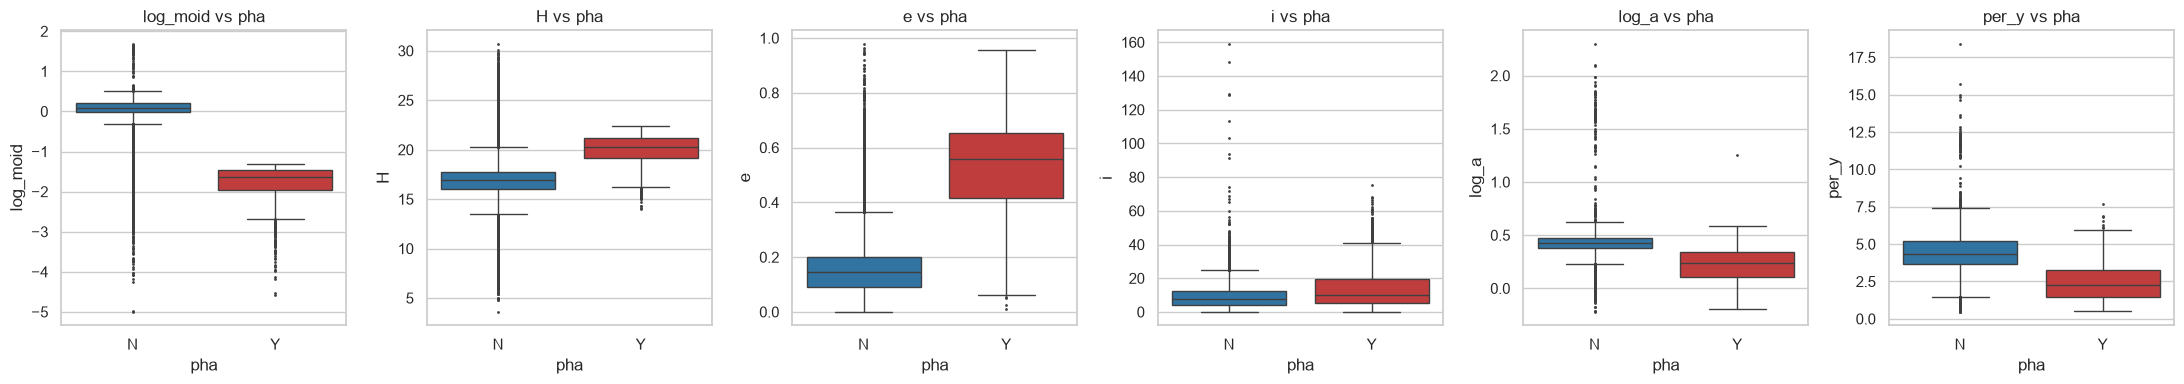

In [8]:
# Balanced VIEW for drawing only: all PHAs + 50k random non-PHAs
bal = pd.concat([lab[lab["pha"] == "Y"], lab[lab["pha"] == "N"].sample(50_000, random_state=RNG)])
bal = bal.assign(log_moid=np.log10(bal["moid"].clip(lower=1e-5)), log_a=np.log10(bal["a"]))

fig, axes = plt.subplots(1, 6, figsize=(22, 4))
for ax, c in zip(axes, ["log_moid", "H", "e", "i", "log_a", "per_y"]):
    d = bal if c != "per_y" else bal[bal["per_y"] < 20]
    sns.boxplot(data=d, x="pha", y=c, ax=ax, order=["N", "Y"], palette=["tab:blue", "tab:red"], fliersize=1)
    ax.set_title(f"{c} vs pha")
savefig("02_pha_boxplots")

### `moid` vs `H` — the PHA definition is visible in the picture
PHA ⇔ `moid ≤ 0.05 AU` **and** `H ≤ 22`. The red points should sit entirely inside the box formed by those two lines.

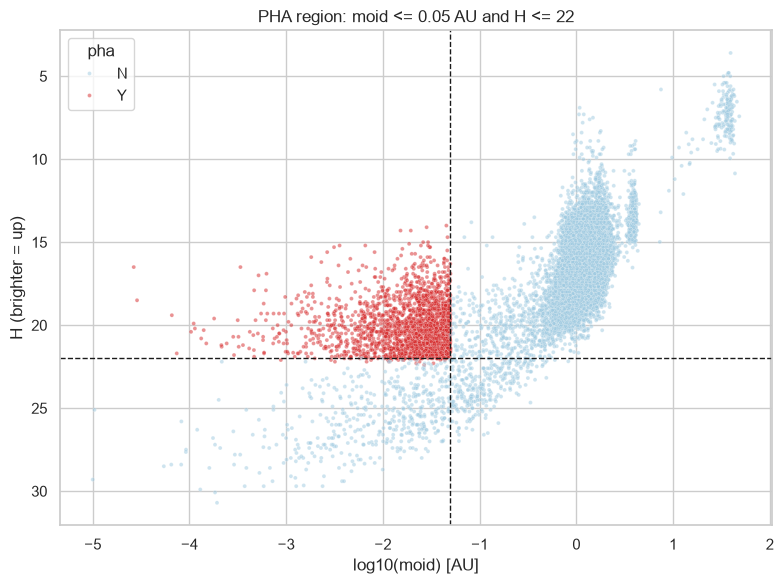

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=bal, x="log_moid", y="H", hue="pha", hue_order=["N", "Y"],
                palette=["#9ecae1", "tab:red"], s=8, alpha=0.5, ax=ax)
ax.axvline(np.log10(0.05), color="k", ls="--", lw=1); ax.axhline(22, color="k", ls="--", lw=1)
ax.invert_yaxis(); ax.set_xlabel("log10(moid) [AU]"); ax.set_ylabel("H (brighter = up)")
ax.set_title("PHA region: moid <= 0.05 AU and H <= 22")
savefig("02_moid_vs_H_pha")

In [10]:
# PHA rate by orbital class (labelled rows only)
rate = lab.groupby("class")["pha"].agg(n="size", pha_n=lambda s: (s == "Y").sum())
rate["pha_rate_%"] = (rate["pha_n"] / rate["n"] * 100).round(3)
display(rate.sort_values("pha_rate_%", ascending=False))

# PHA rate by moid bin and H bin
lab2 = lab.assign(
    moid_bin=pd.cut(lab["moid"], [0, 0.01, 0.05, 0.1, 0.3, 1, 100], include_lowest=True),
    H_bin=pd.cut(lab["H"], [0, 18, 20, 22, 24, 26, 40]),
)
print("\nPHA rate % by moid bin:"); print((lab2.groupby("moid_bin")["pha"].apply(lambda s: (s=="Y").mean()*100)).round(3).to_string())
print("\nPHA rate % by H bin:");    print((lab2.groupby("H_bin")["pha"].apply(lambda s: (s=="Y").mean()*100)).round(3).to_string())

,n,pha_n,pha_rate_%
class,,,
IEO,22,6,27.273
APO,12687,1768,13.936
ATE,1729,174,10.064
AMO,8456,118,1.395
AST,75,0,0.000
CEN,504,0,0.000
HYA,4,0,0.000
IMB,19903,0,0.000
MBA,837430,0,0.000



PHA rate % by moid bin:
moid_bin
(-0.001, 0.01]    10.691
(0.01, 0.05]      23.457
(0.05, 0.1]        0.000
(0.1, 0.3]         0.000
(0.3, 1.0]         0.000
(1.0, 100.0]       0.000

PHA rate % by H bin:
H_bin
(0, 18]      0.027
(18, 20]     0.464
(20, 22]    13.164
(22, 24]     0.370
(24, 26]     0.000
(26, 40]     0.000


## 6. Bivariate: features vs `diameter` (Case 2)

Rows with diameter+H+albedo: 131,237


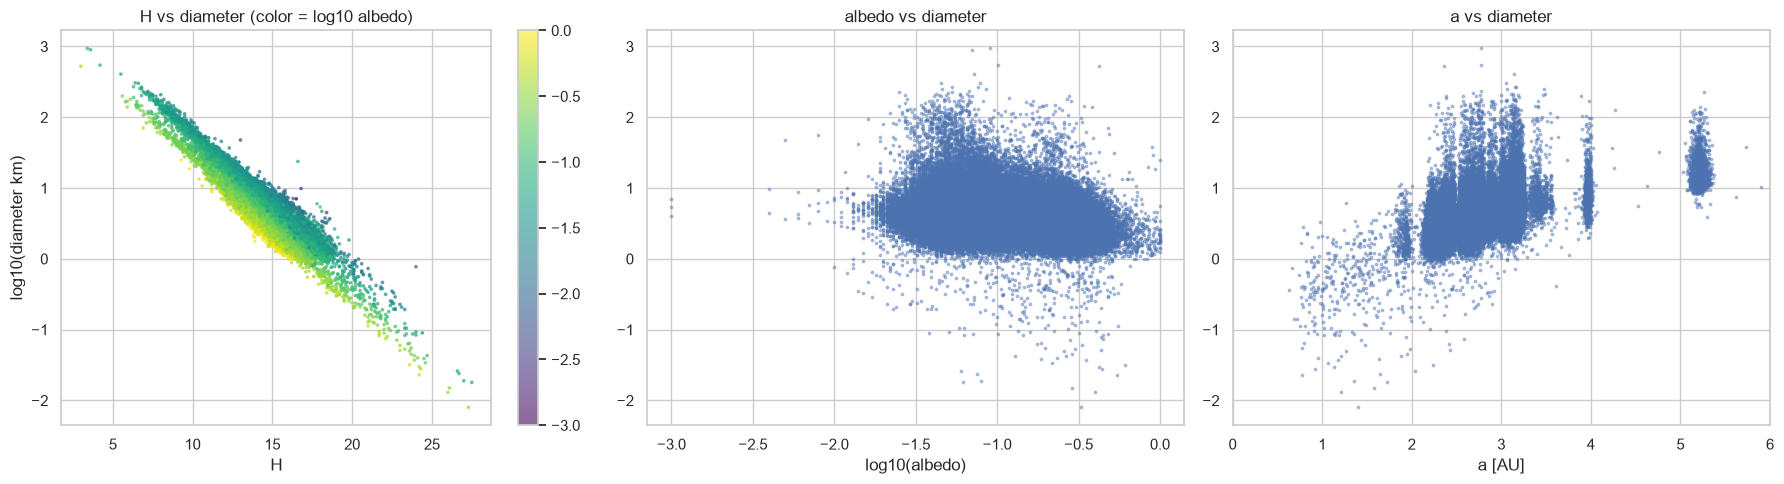

In [11]:
dd = df.dropna(subset=["diameter", "H", "albedo"]).copy()
dd = dd[(dd["diameter"] > 0) & (dd["albedo"] > 0)]
print(f"Rows with diameter+H+albedo: {len(dd):,}")
ds = dd.sample(min(100_000, len(dd)), random_state=RNG)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sc = axes[0].scatter(ds["H"], np.log10(ds["diameter"]), c=np.log10(ds["albedo"]), s=3, cmap="viridis", alpha=0.6)
axes[0].set_xlabel("H"); axes[0].set_ylabel("log10(diameter km)"); axes[0].set_title("H vs diameter (color = log10 albedo)")
plt.colorbar(sc, ax=axes[0])

axes[1].scatter(np.log10(ds["albedo"]), np.log10(ds["diameter"]), s=3, alpha=0.4)
axes[1].set_xlabel("log10(albedo)"); axes[1].set_title("albedo vs diameter")

axes[2].scatter(ds["a"], np.log10(ds["diameter"]), s=3, alpha=0.4)
axes[2].set_xlim(0, 6); axes[2].set_xlabel("a [AU]"); axes[2].set_title("a vs diameter")
savefig("02_diameter_bivariate")

### Leakage check: `diameter` is a formula of `H` and `albedo`
Standard relation: **D(km) = 1329 / √albedo × 10^(−H/5)**. If this reproduces the target almost exactly, then H + albedo make Case 2 trivial.

In [12]:
dd["D_formula"] = 1329 / np.sqrt(dd["albedo"]) * 10 ** (-dd["H"] / 5)
ratio = dd["D_formula"] / dd["diameter"]
r2 = np.corrcoef(np.log10(dd["D_formula"]), np.log10(dd["diameter"]))[0, 1] ** 2
print(f"R^2 (log space) formula vs diameter : {r2:.5f}")
print(f"Ratio formula/diameter  median={ratio.median():.4f}  IQR=({ratio.quantile(.25):.4f}, {ratio.quantile(.75):.4f})")
print(f"Within +-5%: {((ratio-1).abs() < 0.05).mean()*100:.1f}% of rows")

# What if albedo is NOT available? H alone:
r2_H = np.corrcoef(dd["H"], np.log10(dd["diameter"]))[0, 1] ** 2
print(f"R^2 (log diameter ~ H only, linear): {r2_H:.4f}")

R^2 (log space) formula vs diameter : 0.96044
Ratio formula/diameter  median=0.9524  IQR=(0.9053, 1.0006)
Within +-5%: 38.5% of rows
R^2 (log diameter ~ H only, linear): 0.6918


## 7. Correlation & multicollinearity

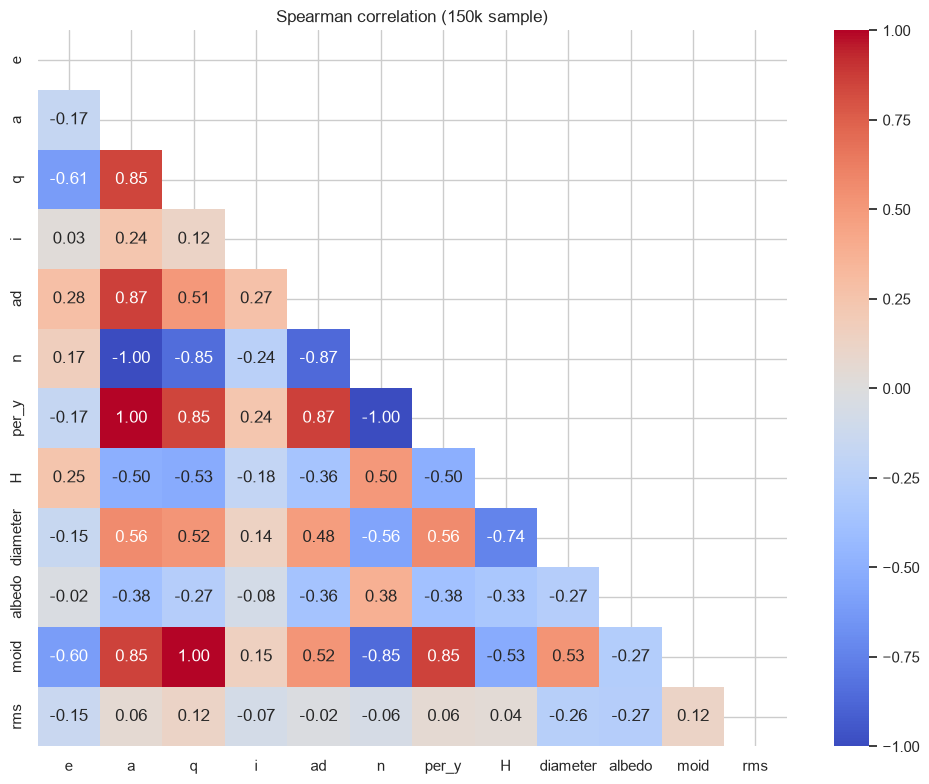

Feature pairs with |Spearman| >= 0.85:


,f1,f2,rho
0,per_y,a,1.000
1,per_y,n,-1.000
2,n,a,-1.000
3,moid,q,0.998
4,ad,a,0.866
5,n,ad,-0.866
6,per_y,ad,0.866
7,moid,n,-0.854
8,moid,a,0.854
9,moid,per_y,0.854


In [13]:
corr_feats = ["e", "a", "q", "i", "ad", "n", "per_y", "H", "diameter", "albedo", "moid", "rms"]
corr = samp[corr_feats].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (150k sample)")
savefig("02_correlation_heatmap")

pairs = (corr.where(~mask).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "f1", "level_1": "f2"}))
pairs = pairs[pairs["rho"].abs() >= 0.85].sort_values("rho", key=abs, ascending=False)
print("Feature pairs with |Spearman| >= 0.85:")
display(pairs.round(3).reset_index(drop=True))

## 8. Orbital structure (feeds Case 3 clustering)

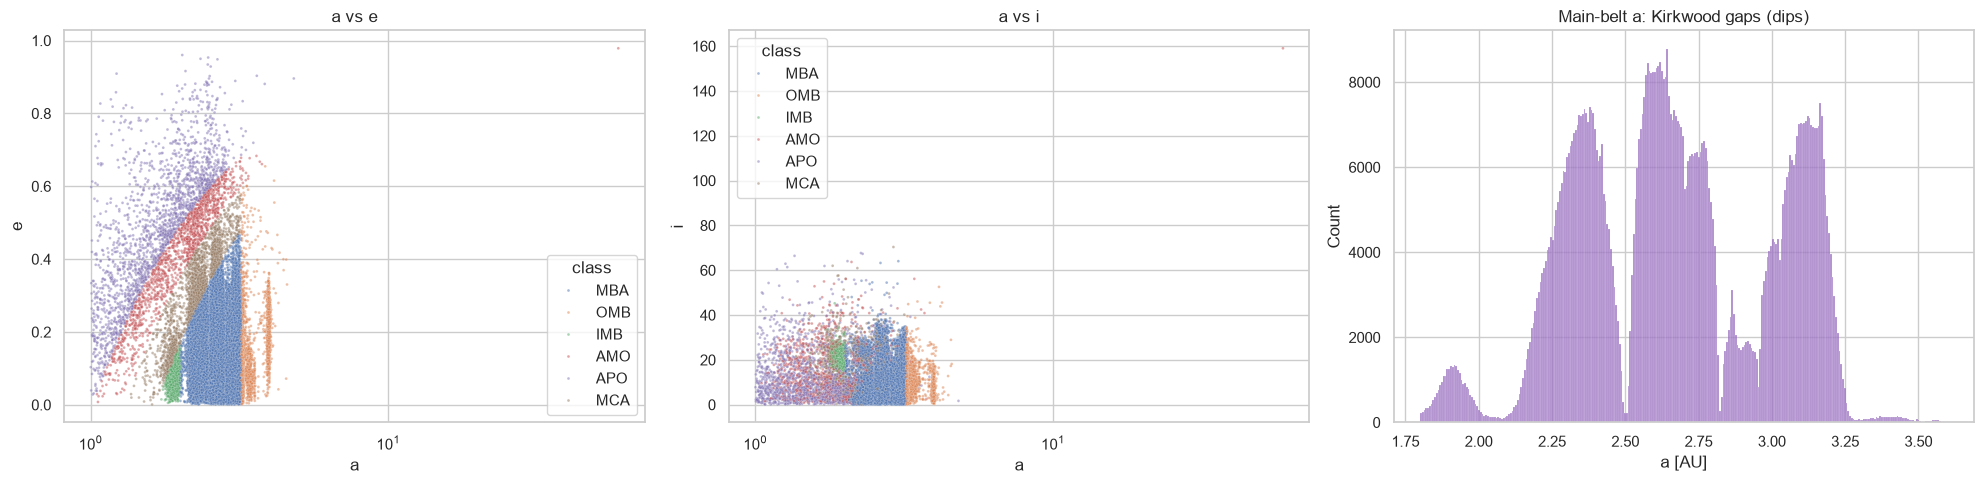

In [14]:
top = df["class"].value_counts().index[:6].tolist()
s2 = samp[samp["class"].isin(top)]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=s2, x="a", y="e", hue="class", s=4, alpha=0.5, ax=axes[0]); axes[0].set_xscale("log"); axes[0].set_title("a vs e")
sns.scatterplot(data=s2, x="a", y="i", hue="class", s=4, alpha=0.5, ax=axes[1]); axes[1].set_xscale("log"); axes[1].set_title("a vs i")

mb = df.loc[df["a"].between(1.8, 3.6), "a"]
sns.histplot(mb, bins=300, ax=axes[2], color="tab:purple"); axes[2].set_title("Main-belt a: Kirkwood gaps (dips)")
axes[2].set_xlabel("a [AU]")
savefig("02_orbital_structure")

### Cyclic angles `om`, `w`, `ma` (0-360°)
Distance-based clustering (K-Means/DBSCAN) treats 359° and 1° as far apart. Decision needed in 03: encode with sin/cos, or drop.

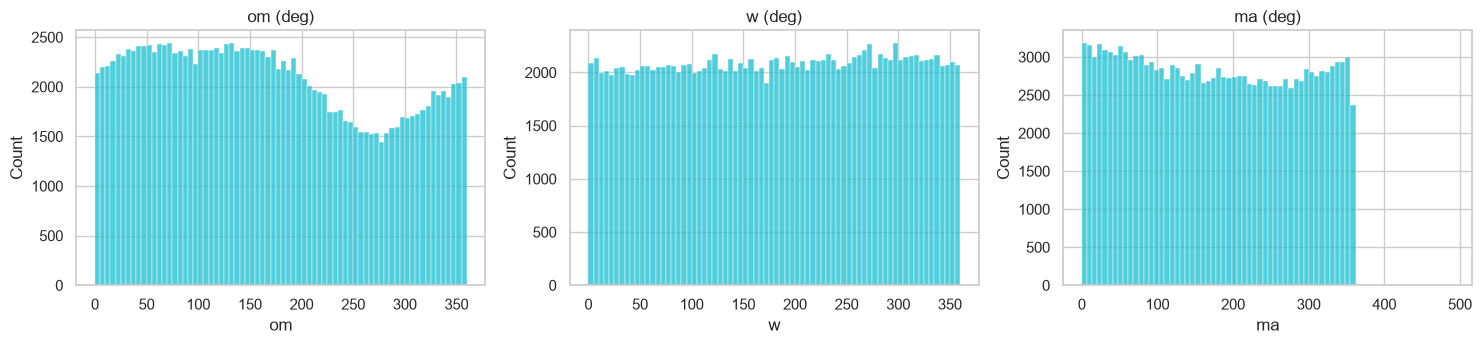

        om      w      ma
min    0.0    0.0  -70.70
max  360.0  360.0  491.62


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, c in zip(axes, ["om", "w", "ma"]):
    sns.histplot(samp[c], bins=72, ax=ax, color="tab:cyan"); ax.set_title(f"{c} (deg)")
savefig("02_angle_distributions")
print(df[["om", "w", "ma"]].describe().loc[["min", "max"]].round(2))

## 9. Missingness patterns

In [16]:
mp = pd.DataFrame({
    "n": df.groupby("class").size(),
    "pha_missing_%":      df.groupby("class")["pha"].apply(lambda s: s.isna().mean() * 100),
    "diameter_present_%": df.groupby("class")["diameter"].apply(lambda s: s.notna().mean() * 100),
}).round(2)
display(mp.sort_values("n", ascending=False))

print("\npha missing vs moid missing:")
print(pd.crosstab(df["pha"].isna(), df["moid"].isna(), rownames=["pha missing"], colnames=["moid missing"]))

,n,pha_missing_%,diameter_present_%
class,,,
MBA,855954,2.16,14.60
OMB,28355,1.90,26.52
IMB,20360,2.24,2.78
MCA,18685,1.76,1.92
APO,12687,0.00,3.83
AMO,8457,0.01,3.17
TJN,8221,0.74,22.78
TNO,3468,0.17,0.35
ATE,1729,0.00,5.49



pha missing vs moid missing:
moid missing   False  True 
pha missing                
False         938603      0
True               0  19921


## 10. Save EDA tables

In [17]:
stats.to_csv(RES_DIR / "02_numeric_stats.csv")
out.to_csv(RES_DIR / "02_outlier_summary.csv")
rate.to_csv(RES_DIR / "02_pha_rate_by_class.csv")
corr.to_csv(RES_DIR / "02_spearman_corr.csv")
print("Saved to", RES_DIR)

Saved to c:\Projects\Planetary_Defense_Analytics\reports\results
